# Initial testing: stdpopsim and 1KGP

Compare the inferred panels for the two 100-individual, 10 Mb datasets.
All figures place stdpopsim on the left and 1KGP on the right. Population
labels are read directly from the pipeline's annotated statistics CSVs.

In [71]:
import pathlib

import numpy as np
import pandas as pd

from ch5 import nb_plot

repository_dir = pathlib.Path.cwd()

In [72]:
match_eval_dir = pathlib.Path("~/work/tsinfer-match-eval/data/match_eval").expanduser()
dataset_names = {"stdpopsim": "out_of_africa_n100_10mbp", "1KGP": "tgp_chr20_n100"}
focal_stats_by_dataset = {}
focal_ancestors_by_dataset = {}
haplotype_counts = {}
for label, dataset in dataset_names.items():
    stats_path = (
        match_eval_dir / "dataframes" / f"{dataset}_inferred_focal_ancestor_stats.csv"
    )
    stats = pd.read_csv(stats_path, dtype={"sample_id": str, "population": str})
    if "population" not in stats.columns or stats["population"].isna().any():
        raise ValueError(
            f"{stats_path} must contain pipeline-annotated population labels"
        )
    focal_stats_by_dataset[label] = stats
    focal_path = (
        match_eval_dir / "focal_ancestors" / f"{dataset}_inferred_focal_ancestors.npz"
    )
    with np.load(focal_path, allow_pickle=False) as focal_data:
        focal_ancestors_by_dataset[label] = pd.DataFrame(
            {
                "ancestor_id": focal_data["ancestor_id"],
                "derived_ac": focal_data["derived_ac"],
            }
        )
        haplotype_counts[label] = len(focal_data["sample_id"])

In [73]:
ac_cutoffs = sorted(focal_stats_by_dataset["stdpopsim"]["ac_cutoff"].unique())
for stats in focal_stats_by_dataset.values():
    if sorted(stats["ac_cutoff"].unique()) != ac_cutoffs:
        raise ValueError("The compared datasets must use the same allele-count cutoffs")
if len(set(haplotype_counts.values())) != 1:
    raise ValueError("Shared frequency-cutoff rows require equal haplotype counts")
num_haploid_samples = haplotype_counts["stdpopsim"]

## Cumulative inferred ancestors by focal frequency

Count each inferred ancestor once using its focal allele count in the NPZ.
Dashed lines mark the coverage cutoffs divided by the number of haplotypes.
These are panel-wide counts, before restricting to ancestors associated with
a particular haplotype. Count divided by total haplotypes is the focal
frequency coordinate used here, including for the cutoff labels.

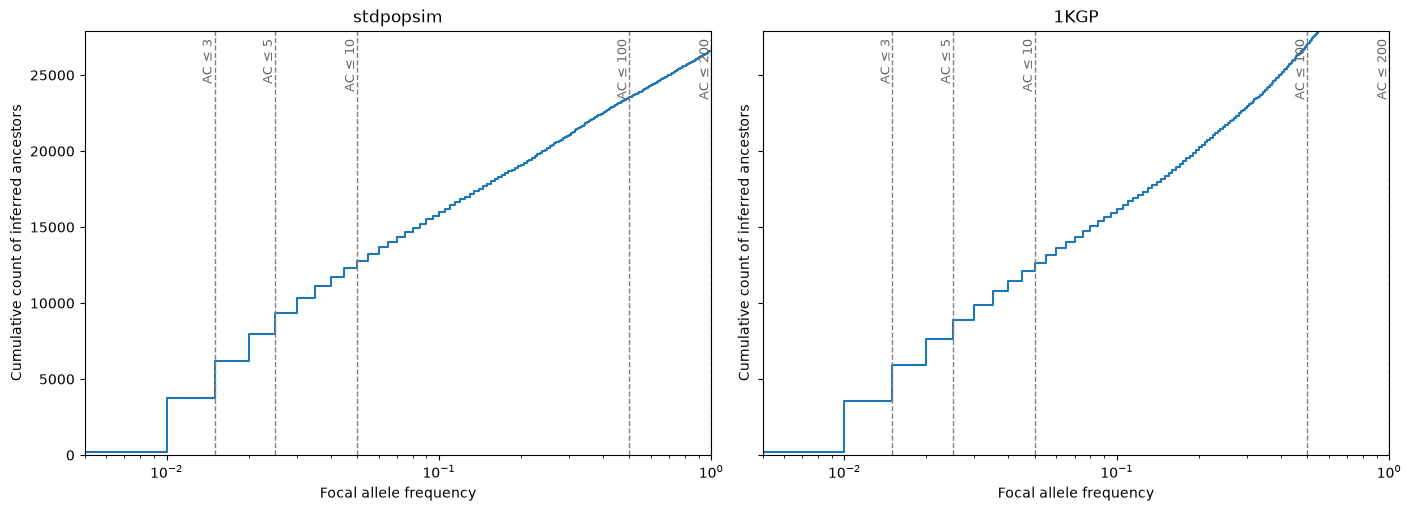

In [75]:
nb_plot.plot_cumulative_inferred_ancestors_by_focal_frequency(
    ac_cutoffs=ac_cutoffs,
    dataset_names=dataset_names,
    focal_ancestors_by_dataset=focal_ancestors_by_dataset,
    haplotype_counts=haplotype_counts,
    figsize=(14, 5),
)

## Focal coverage across haploid samples

Each row in a statistics CSV is one haplotype at one cumulative allele-count
cutoff. Matching uses the full panel at every cutoff; the coverage fraction
counts inference sites copied from eligible focal ancestors. Box plots show
these fractions at the same frequency cutoffs in both datasets.

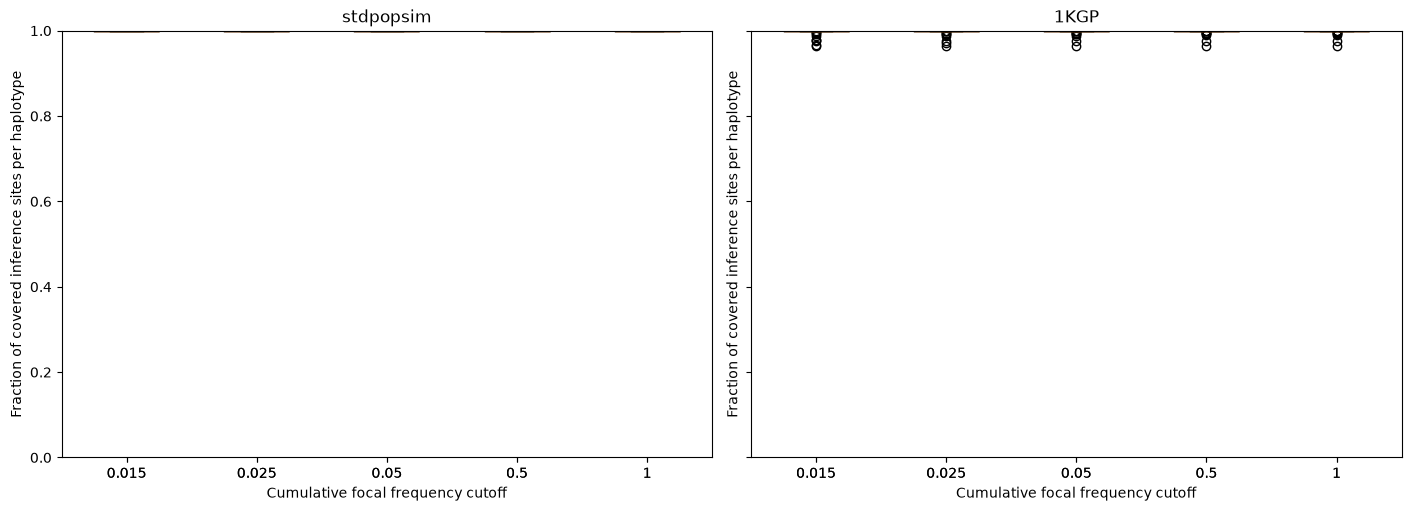

In [76]:
nb_plot.plot_focal_coverage_across_haploid_samples(
    ac_cutoffs=ac_cutoffs,
    dataset_names=dataset_names,
    focal_stats_by_dataset=focal_stats_by_dataset,
    num_haploid_samples=num_haploid_samples,
    figsize=(14, 5),
)

## Match score and focal coverage at each frequency cutoff

`path_log_likelihood` is a normalized log score: values closer to zero
indicate fewer mismatch and switch penalties. Each haplotype's score stays
fixed across cutoffs; only its focal coverage changes.

Each row compares one frequency cutoff, with stdpopsim on the left and 1KGP
on the right. Population codes shared by both datasets use the same colour
for points, fitted lines, and stacked marginal histograms. Coloured lines
and legend `r` values show within-population fits and Pearson correlations;
the dashed grey line and annotation show the pooled fit and correlation.
All panels share score/coverage limits and histogram bin edges. Populations
with constant scores have an undefined correlation (r = n/a) and no fitted line.

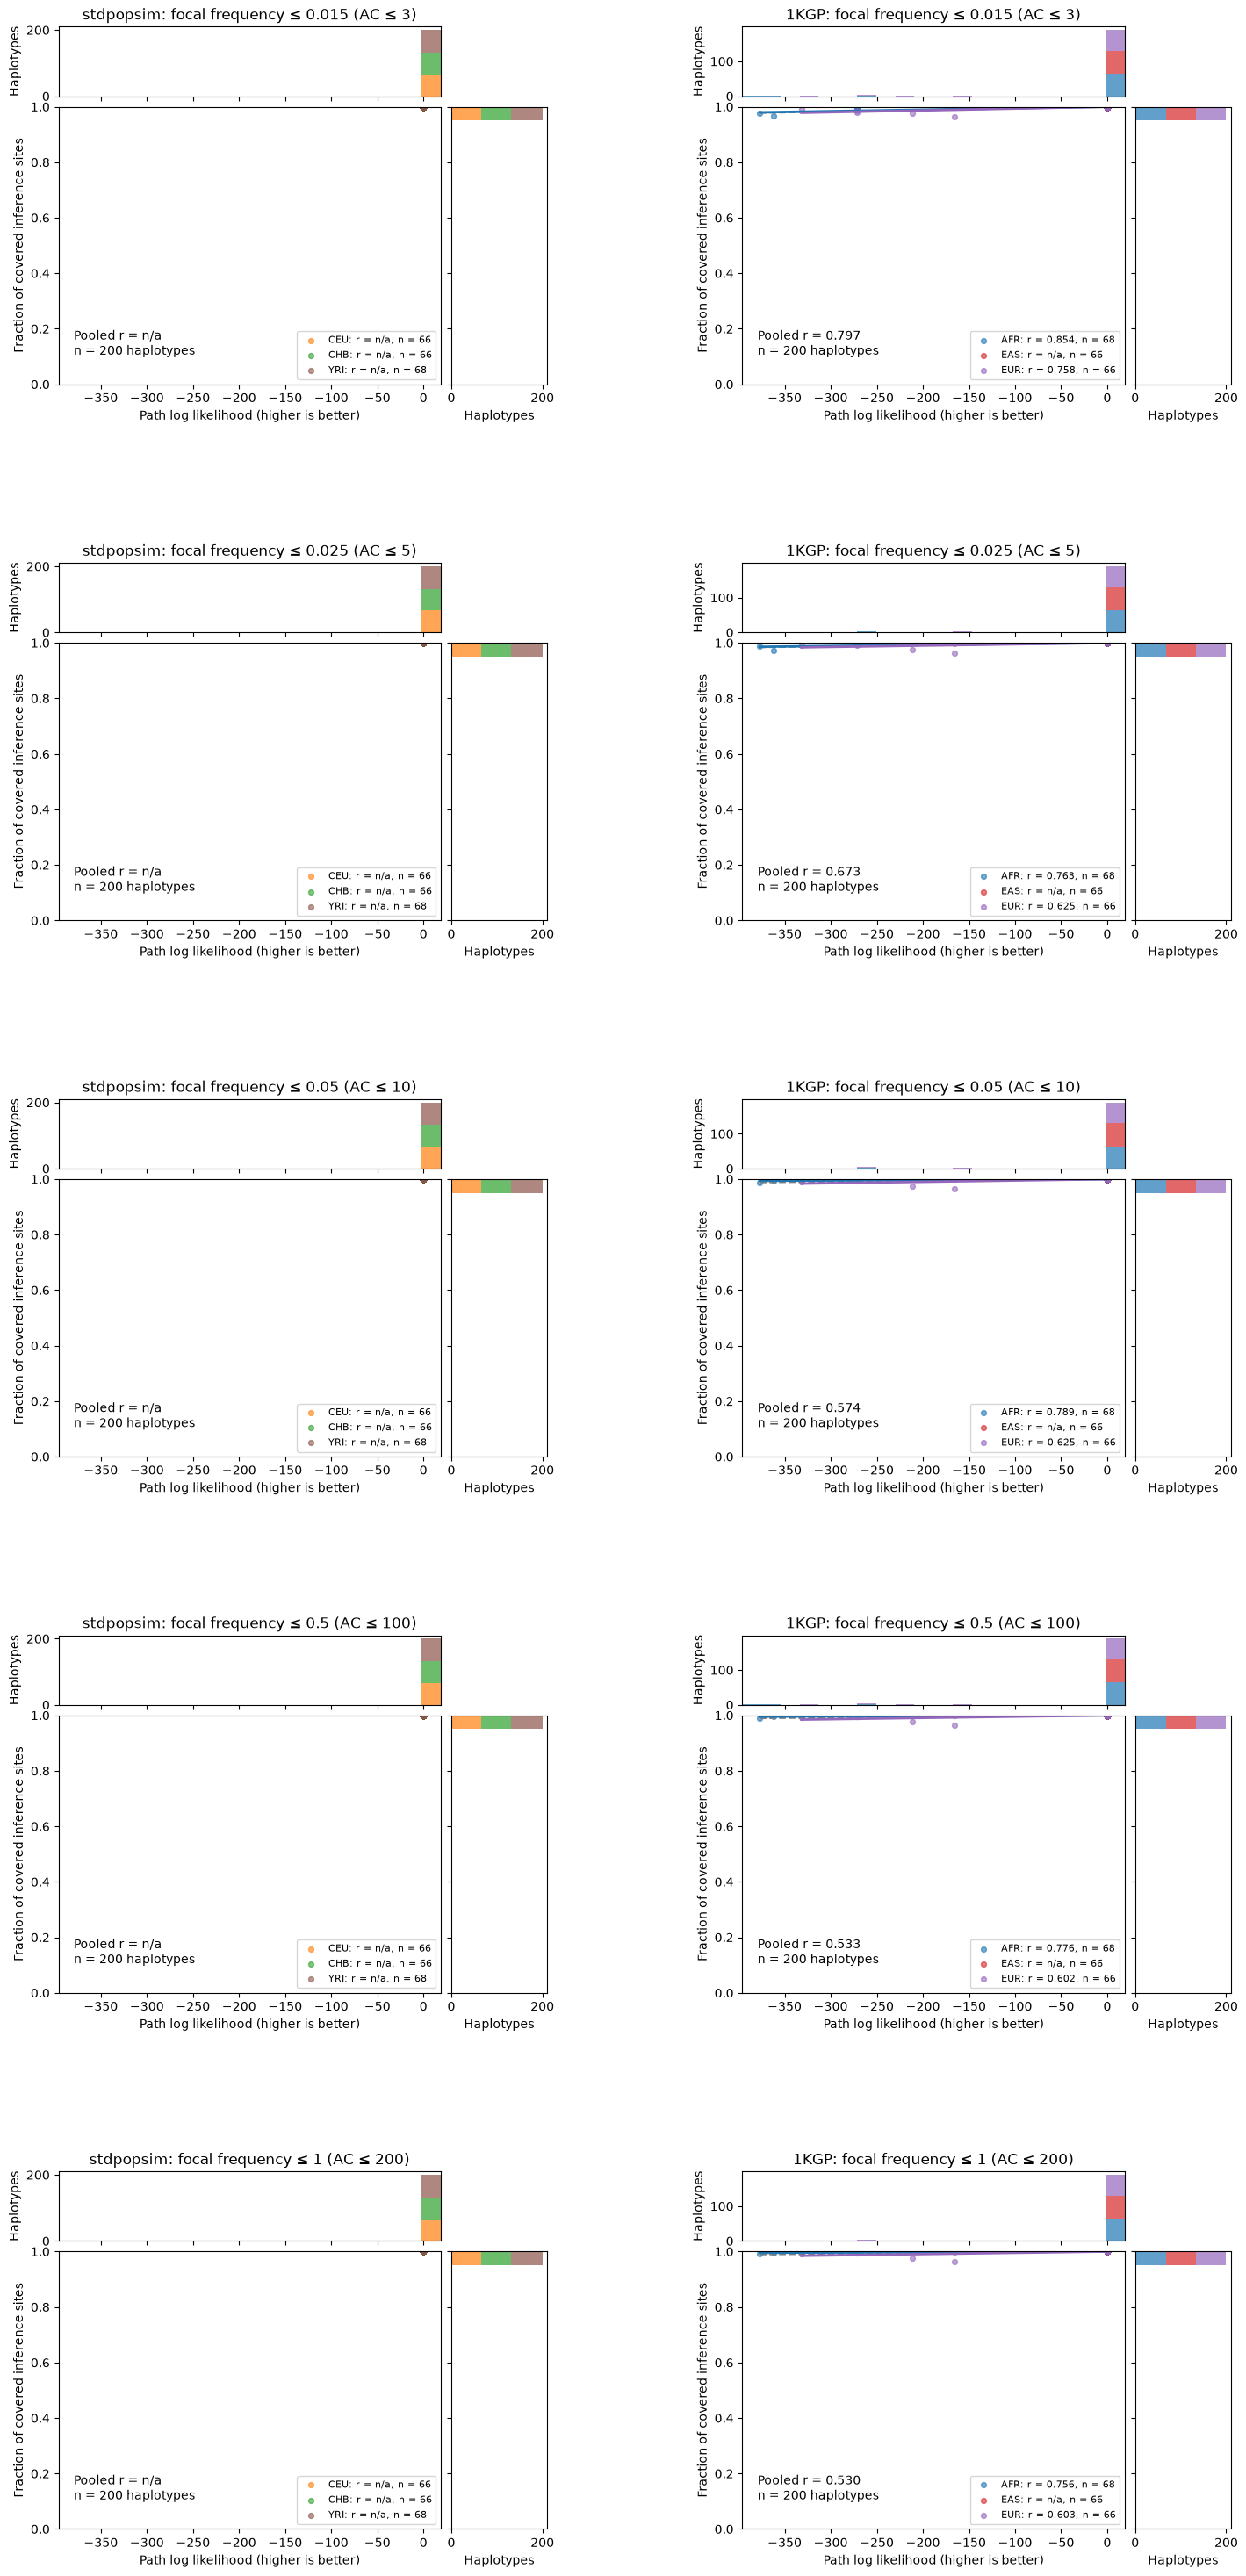

In [78]:
combined_stats = pd.concat(focal_stats_by_dataset.values(), ignore_index=True)
population_names = sorted(combined_stats["population"].unique())
nb_plot.plot_match_score_and_focal_coverage_at_each_frequency_cutoff(
    ac_cutoffs=ac_cutoffs,
    combined_stats=combined_stats,
    dataset_names=dataset_names,
    focal_stats_by_dataset=focal_stats_by_dataset,
    num_haploid_samples=num_haploid_samples,
    population_names=population_names,
)